# Story 3 companion · the two canonical robustness grids

**Question:** Which changes alter decisions, and which actually change correctness? These are the only full-population transformation grids in the main results: label-change rate and accuracy across **3,421 TEST images**, eight transformations and all ten tested levels, with noise repeats averaged within image.

Run from the repository root; no model inference is performed. Titles give the physical units, dashed accuracy lines show the unmodified baseline, and common 0–100% axes support within-metric model comparisons; different transformation ranges are **not equal-strength perturbations**. Return to [02_model_behavior.ipynb](02_model_behavior.ipynb#story-3) for distinct evidence: class probabilities for selected small flips, a resizing/noise control, and recovery-versus-new-error decomposition.

Full-test curves and the balanced 96-image interpolation probe have different class weights/denominators and should not be combined as one estimate. Historical multi-panel confidence/entropy plots and severity-averaged summaries remain in [archived/analysis_history.ipynb](archived/analysis_history.ipynb), not repeated here.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

with np.load('data/bloodmnist.npz',allow_pickle=False) as saved:
    labels=saved['test_labels'].ravel()
with np.load('predictions/stability.npz',allow_pickle=False) as saved:
    assert str(saved['split'])=='test' and str(saved['noise_seed_scope'])=='original test index'
    np.testing.assert_array_equal(saved['indices'],np.arange(len(labels)))
    np.testing.assert_array_equal(saved['labels'],labels)
    assert len(labels)==3421
    baseline=saved['baseline']
    model_names=saved['model_names'].tolist()
    checkpoints=saved['checkpoints'].tolist()
    levels={key[7:]:saved[key] for key in saved.files if key.startswith('levels_')}
    base_class=baseline.argmax(-1)
    baseline_accuracy=(base_class==labels).mean(-1)
    curves={'Label changes':{},'Accuracy':{}}
    for kind,values in levels.items():
        p=saved[kind]
        assert p.shape==(3,10,3 if kind=='noise' else 1,len(labels),8)
        assigned=p.argmax(-1)
        # Equal weight per original image; the repeated-noise mean is not an enlarged sample.
        curves['Label changes'][kind]=(assigned!=base_class[:,None,None,:]).mean((2,3))
        curves['Accuracy'][kind]=(assigned==labels).mean((2,3))
model_colors=['#2678ad','#3b9956','#c25a7c']
axis_labels={'rotation':'Rotation (degrees)','translation':'Translation (pixels)',
             'brightness':'Brightness factor','blur':'Blur radius (pixels)','noise':'Noise σ',
             'green_scale':'Green factor','red_scale':'Red factor','blue_scale':'Blue factor'}
for name,accuracy,path in zip(model_names,baseline_accuracy,checkpoints):
    print(f'{name}: original accuracy {accuracy:.2%} · {path}')
def plot_comparison(metric):
    fig,axes=plt.subplots(2,4,figsize=(16,7),sharey=True,layout='constrained')
    for ax,(kind,values) in zip(axes.flat,levels.items()):
        for m,name in enumerate(model_names):
            ax.plot(values,curves[metric][kind][m],'o-',color=model_colors[m],label=name,ms=4)
            if metric=='Accuracy':
                ax.axhline(baseline_accuracy[m],color=model_colors[m],ls='--',alpha=.4)
        ax.set(title=axis_labels[kind],ylim=(0,1),yticks=np.linspace(0,1,5))
        ax.yaxis.set_major_formatter(PercentFormatter(1,decimals=0))
        ax.grid(alpha=.2)
    fig.legend(*axes[0,0].get_legend_handles_labels(),loc='outside lower center',ncol=3)
    fig.suptitle(f'{metric} · all {len(labels):,} TEST images · common 0–100% axes; no severity averaging')
    plt.show()

resnet18: original accuracy 96.61% · weights_bloodmnist/resnet18_224_1.pth
resnet50: original accuracy 95.73% · weights_bloodmnist/resnet50_28_1.pth
vit: original accuracy 96.99% · models/vit


## Do predictions keep the same label?

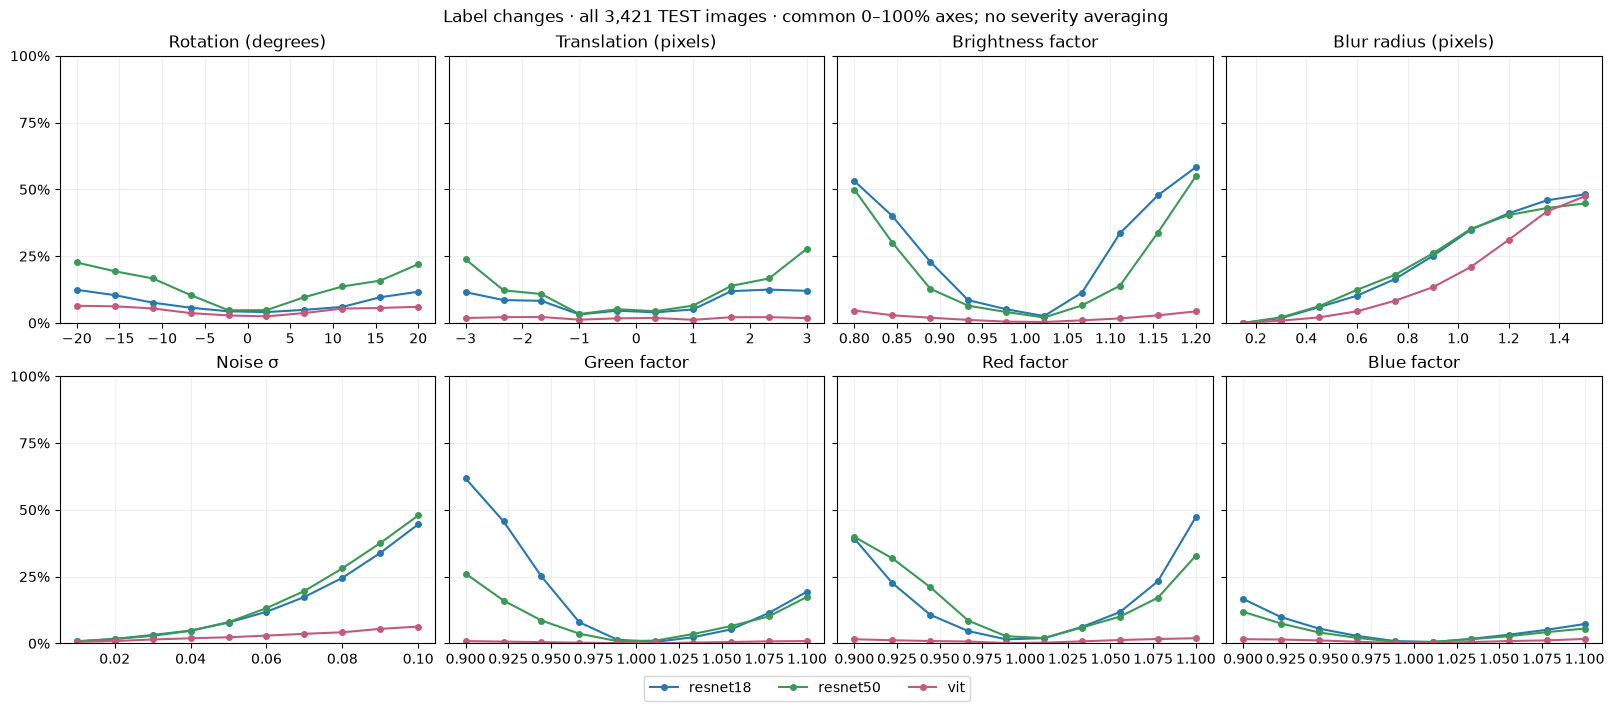

In [2]:
plot_comparison('Label changes')

Compare labels within each transformation at its actual severity, not severity-averaged scores across unrelated ranges. At +20° rotation, labels change for 11.7%, 22.0% and 6.1% of images for ResNet18, ResNet50 and ViT, whereas at blur radius 1.5 the rates are 48.1%, 44.7% and 47.4%. ViT is more consistent under this rotation setting but not under strong detail removal, and a label switch alone does not say whether correctness improved.

## Are the predictions correct? — dashed lines show original accuracy

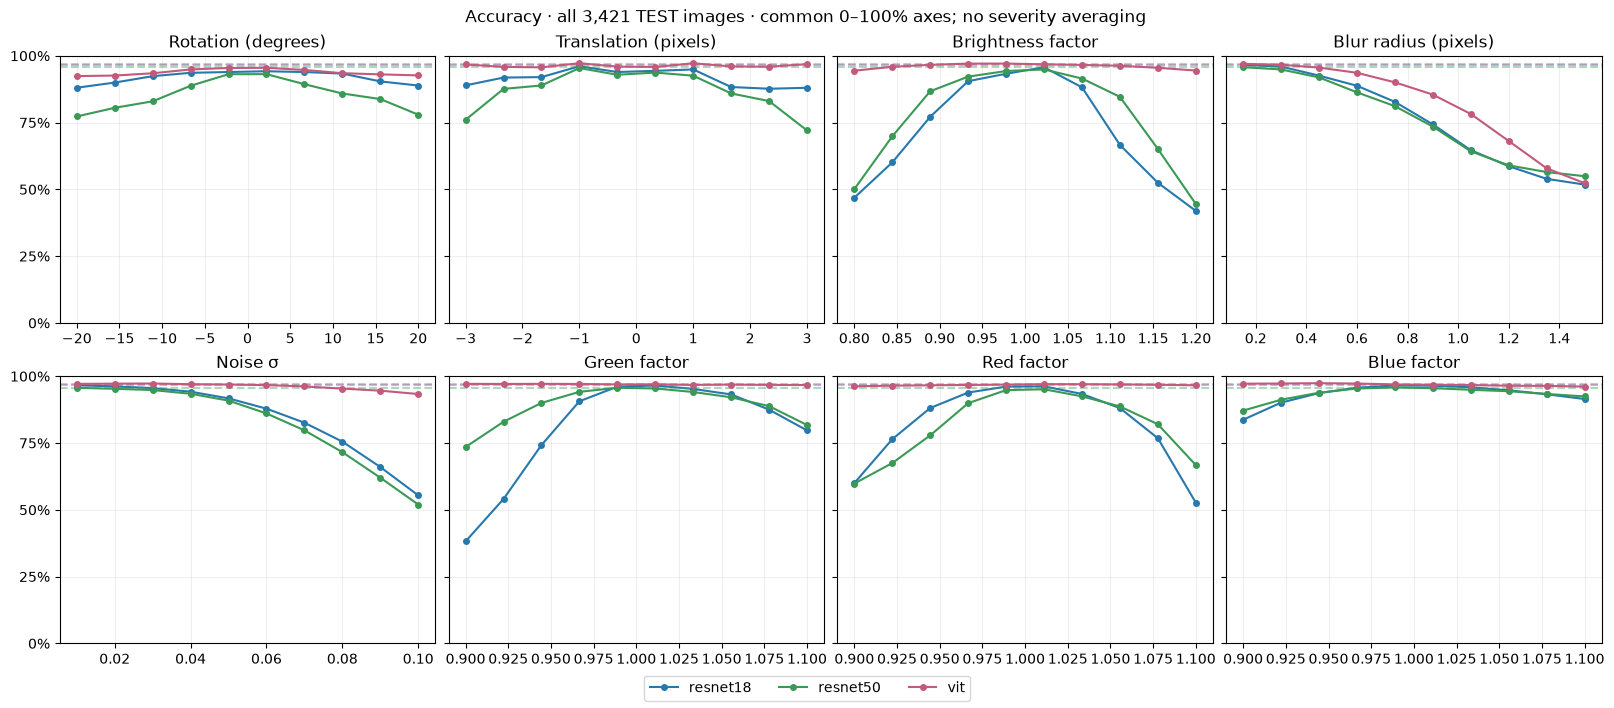

In [3]:
plot_comparison('Accuracy')

Compare each curve with its own original accuracy and keep the tested severity explicit. At brightness ×0.8, accuracy is 46.9%, 50.1% and 94.4% for ResNet18, ResNet50 and ViT, but at blur radius 1.5 it converges to 51.8%, 54.9% and 52.3%. ViT's relative advantage is therefore intervention-specific, while the separate interpolation control cautions against attributing the native-pipeline noise gap to architecture alone.

## Interpretation and interactive follow-through

Use [02_model_behavior.ipynb](02_model_behavior.ipynb#story-3) to decompose recoveries versus newly wrong predictions, inspect tiny-change examples with all eight probabilities, and check how interpolation confounds the noise comparison. Its [offline explorer](visualizations/transformation_explorer.html) needs no model server; the separate live editor/workbench is archived and not part of this workflow. The targeted 96-image interpolation control does not replace these full-test curves or justify an architecture-only robustness claim.